# 20. From photographs to a static scene

[Course plan](../../README.md)

Nine photographs of a sculpture are on the table. Their camera poses are known. One image can stay face down while the other eight guide the fit. Turning it over at the end shows what the model managed to learn about the space between cameras.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'en'


## 1. The starting point

The colored-splat experiment starts with known centers and sizes. All splats are gray. Each color step sees three training views together. In the photographic capture, the centers come from sparse reconstruction. Changing the selected camera shows another image of the same model. A sideways camera shift opens a further view without a reference photograph. The browser fits RGB with geometry fixed. Later in the Python calculation, centers, three widths, rotation and opacity also become trainable.


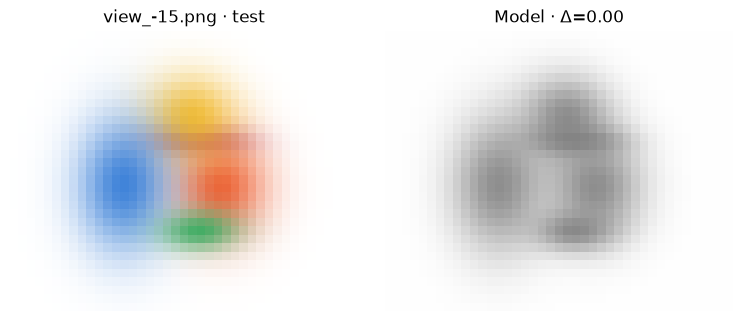

In [2]:
frames, initial = synthetic_capture()
def small_view(steps, offset):
    model, _ = fit_colors(initial, frames, int(steps))
    return view_figure(frames, model, 1, offset, lang)
display(small_view(0,0)); plt.close()
controls(small_view, steps=(0,24,1,0), offset=(-.2,.2,.005,0))


## 2. From one pixel to a first step

We can follow just the red channel. A splat starts at $c=0.5$. In this pixel its compositing weight is $w=T\alpha=0.6$. White background fills the remaining 0.4. The prediction is $P=0.6\cdot0.5+0.4\cdot1=0.7$. The photograph gives $Y=0.58$. The residual $P-Y=0.12$ has square $0.0144$. Adding 0.01 to the red channel would increase $P$ by $0.6\cdot0.01=0.006$. The current red is already too bright.

The derivative of squared error with respect to this color is $2(P-Y)w$. The 2 comes from the square, the residual retains its sign, and $w$ measures how much of the ray can see this splat. Numerically this is $2\cdot0.12\cdot0.6=0.144$. At learning rate 0.5, the new value is $0.5-0.5\cdot0.144=0.428$. Now $P=0.6568$ and the squared residual is about $0.00590$. The full calculation combines pixels from all training views. Empty areas carry little information about a particular splat.

Why are these first steps cheap? Fixed shapes give fixed weights. For pixel $j$ we store $w_{ji}$, its weight from visible splat $i$, and $b_j$, its fraction of white background. Then $P_j=b_j+\sum_i w_{ji}c_i$. The sum adds each splat’s contribution. With weights 0.6 and 0.1, background 0.3 and colors 0.5 and 0.2, the prediction is $0.3+0.6\cdot0.5+0.1\cdot0.2=0.62$. Each weight-matrix column corresponds to a splat and each row to a pixel. Summed products of these weights can be prepared just once, so another RGB update avoids reprojection. Each channel stays between 0 and 1.


In [3]:
w,c,b,target = .6,.5,.4,.58
pred = b+w*c
updated = c-.5*2*(pred-target)*w
print("color:", c, "→", updated)
print("loss:", (pred-target)**2, "→", (b+w*updated-target)**2)
assert (b+w*updated-target)**2 < (pred-target)**2


color: 0.5 → 0.428
loss: 0.0144 → 0.005898240000000014


## 3. A capture that travels with the model

Now the targets are real photographs from **PhysicalAI-NuRec-PPISP, struktur28_auto, NVIDIA Corporation, CC BY 4.0**. The course subset contains nine undistorted, adapted 160 × 120 images. Eight training photographs supplied 117 triangulated points at known camera poses. The ninth image’s pixels supplied neither those point locations nor their colors. For a quick fit we start from 24 points and reduce the images to 40 × 30. The initial splats are gray with equal opacity. A larger cloud can carry finer details at higher cost per step. [Photograph provenance and adaptations](https://github.com/HeinrichWirth/gaussian-splatting-course/tree/main/data/photographic-example)

The **capture** folder below contains PNGs, cameras, the initial parameters and train/test labels. The notebook’s working directory gets a **static-scene-result** folder containing the result and a single-file capture for the website. `out.resolve()` gives its location. For another shoot, `load_colmap(text_model, images_dir, test_names=[...])` takes the two directories from lesson 19 and the names of held-out photographs. These names match images.txt, including any subdirectories and extensions. Keeping the evaluation view apart from near-duplicate burst shots makes it more informative.


When a personal reconstruction was estimated from all photographs, the loader split excludes held-out RGB from the gradients. Its initial 3D points and poses may still depend on held-out features. A stricter evaluation triangulates the initial cloud from training observations alone and supplies the test pose separately. The included example separates pixels and tracks that way, with original camera calibration supplied for the entire capture.

In [4]:
photos, seed = photo_capture(max_side=40, max_points=24)
out = Path.cwd() / "static-scene-result"
write_capture(out/"capture", photos, seed)
photos, seed = read_capture(out/"capture")
export_browser_capture(photos, seed, out/"capture-browser.json")
warm, color_loss = fit_colors(seed, photos, steps=12)
print("views:", len(photos), "splats:", len(seed["splats"]))
print("train RGB MSE:", round(color_loss[0],6), "→", round(color_loss[-1],6))


views: 9 splats: 24
train RGB MSE: 0.336137 → 0.25423


## 4. Why color alone leaves a gray cloud unfinished

If a splat lands to the left of a stone edge, changing its hue cannot move it. The calculation now has a longer chain. Its 3D center moves into camera coordinates; dividing by depth gives the screen position. Shape and orientation determine the projected covariance. Each pixel gets a weight and transmittance, then RGB, a difference from the photograph and its square. PyTorch traces that chain backward. Every camera sees **the same** scene parameters. Each update first averages errors within a frame and then across the eight training frames.

The three widths must stay positive. We store unrestricted numbers $\ell$ and render the widths $s=\exp(\ell)$. At $\ell=0$, width is 1. At $\ell=-0.6931$, it is about 0.5 scene units. For opacity and color we store $a$ and render $1/(1+\exp(-a))$. At $a=0$ this gives $1/(1+1)=0.5$. Negative inputs move the output toward zero and positive inputs toward one. The four rotation coordinates are divided by their joint length as in lesson 12. Every update therefore yields a valid shape.

The single-color example used an ordinary gradient step. Across the different scene parameters below, Adam tracks an average direction and recent squared gradient magnitudes. Where one parameter repeatedly gives large gradients, normalization reduces its relative update. The code’s 0.017 sets the overall scale. This fit keeps 30 steps and a budget of 24 splats. Directional appearance, density changes and richer losses enter the larger implementation. The small experiment isolates the passage from sparse points to an adjustable image.


saved: static-gaussians.json  RGB MSE: 0.25423 → 0.056428


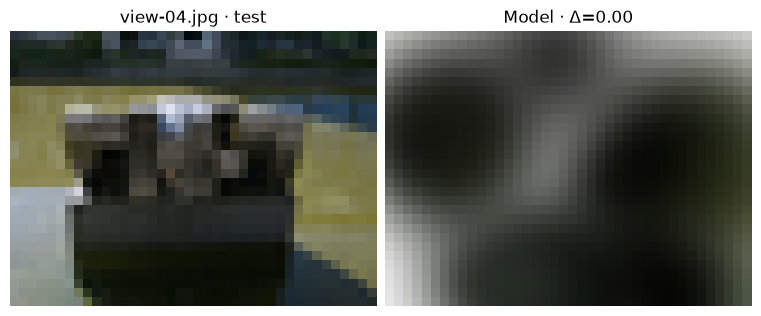

In [5]:
import torch
from reconstruction_fit import refine_scene
torch.set_num_threads(1)
trained, fit_loss = refine_scene(warm, photos, steps=30, rate=.017)
model_path = out/"static-gaussians.json"
model_path.write_text(json.dumps(trained, indent=2, allow_nan=False), encoding="utf8")
opened = json.loads(model_path.read_text(encoding="utf8"))
test_index = next(i for i,f in enumerate(photos) if f["split"]=="test")
f = photos[test_index]
h,w = f["rgb"].shape[:2]
assert np.allclose(render_scene(opened,f["camera"],w,h),render_scene(trained,f["camera"],w,h))
print("saved:", model_path.name, " RGB MSE:", round(fit_loss[0],6), "→", round(fit_loss[-1],6))
display(view_figure(photos, opened, test_index, lang=lang)); plt.close()


## 5. What the viewer opens

**static-gaussians.json** stores three center coordinates, three scales, four rotation coordinates, three color channels and one opacity per splat. Camera data stays with the capture because an image depends on both the scene and the observer. In the web lab, `capture-browser.json` goes into the local JSON field first, followed by `static-gaussians.json` in the same field. The browser uses the capture’s cameras to draw the imported model. A held-out photo can be compared with its render before shifting the camera. At a new pose the error readout disappears because there is no corresponding measurement. This small browser experiment accepts frames up to 128 × 128, up to 128 splats and a cap on total calculation size. Both files stay on the device.

The website opens on the held-out photograph. Its dataset menu also offers **“Trained sculpture · 117 splats”**. This model ran for 1,200 steps on the same eight views, sampling 256 training pixels per step. It opens directly for inspection and export. At full evaluation resolution, 80 × 60, its MSE on view-04 is about 0.00982 or 20.08 dB. The browser compares this trained scene with the same 80 × 60 photograph. [Training the 117-splat model](https://github.com/HeinrichWirth/gaussian-splatting-course/blob/main/scripts/train_photo_reference.py)

Does the model resolve the stone’s details? Its splat budget is small, training directions are limited, and color is constant across viewpoints. Large masses and background color can emerge while narrow edges go missing. The next lesson measures that gap.


In [6]:
controls(lambda view, offset: view_figure(photos, opened, int(view), offset, lang),
         view=list(range(len(photos))), offset=(-.2,.2,.01,0))
print("model file:", model_path.name, " capture file: capture-browser.json")


model file: static-gaussians.json  capture file: capture-browser.json


## 6. The same photographs in the authors’ implementation

A full-size run uses the official project’s dedicated CUDA environment, rasterizer extension and a compatible NVIDIA GPU. The commands run inside the installed reference implementation and reuse **the undistortion results** from lesson 19. The files from `capture/undistorted/images` go in `scene/images`. The contents of `capture/undistorted/sparse`, including binary cameras.bin, images.bin and points3D.bin, go in `scene/sparse/0`. Image filenames continue to match the names in the model. The teaching loader reads the text export; the authors’ implementation uses the binary files.

```sh
python train.py -s scene -m models/sculpture --eval
python render.py -m models/sculpture
python metrics.py -m models/sculpture
SIBR_gaussianViewer_app -m models/sculpture
```

SIBR here is the installed viewer executable in the authors’ bin directory, with an .exe extension on Windows. The `-m` argument points at the **model directory** containing settings and the saved cloud in point_cloud/iteration_…/point_cloud.ply. Its PLY schema and parameterization differ from the teaching JSON. The official trainer changes density and learns spherical-harmonic appearance. With `--eval`, the ordinary COLMAP split holds out every eighth image in filename order. Our experiment explicitly reserves view-04. Comparing the two runs requires the same test poses, resolution and background. [Official project and dependencies](https://github.com/graphdeco-inria/gaussian-splatting) · [Image split implementation](https://github.com/graphdeco-inria/gaussian-splatting/blob/main/scene/dataset_readers.py)

## An experiment

After saving the scene, the camera moves. Which numbers in the Gaussian file must change?

<details><summary>Worked answer</summary>

None. The renderer recomputes pixel positions, footprints and depth order. Training changes the stored scene; navigating a trained scene moves the observer.

</details>
